# Einstein rings: gravity as a lens

Light passing a mass is bent towards it. Einstein's general relativity
predicts twice the Newtonian deflection, 1.75 arcseconds at the edge of
the Sun, which the eclipse expedition of 1919 confirmed. A galaxy or a
cluster bends the light of the sources behind it into several images,
arcs and, for exact alignment, a ring of radius $\theta_E$, the Einstein
ring. A star passing in front of another star brightens it for weeks
(microlensing) without the images ever being resolved.

Optically, a weak gravitational field acts like a medium with the
refractive index $n = 1 - 2\Phi/c^2$, i.e. $n = 1 + R_s/r$ around a point
mass with the Schwarzschild radius $R_s = 2GM/c^2$: a gradient-index lens
of the kind notebook 77 traces. Because the deflection happens within a
small distance of the mass compared with the distances to the observer
and the source, it can also be treated as a thin lens with a deflection
angle that depends on the impact parameter: the lens equation. This
notebook uses `pyoptics.lensing` and `pyoptics.grin` for:

1. light bending in a GRIN medium: the weak field index against
   $\hat\alpha = 2R_s/b$, the exact Schwarzschild metric as an isotropic
   medium against the exact deflection integral, and the photon sphere
   that captures rays with $b < 3\sqrt{3}R_s/2$,
2. the thin lens and the lens equation for a point mass: the two images
   and their magnifications, Einstein radii of stars and galaxies,
3. rings and arcs of extended sources by inverse ray shooting, and the
   magnification of a finite source against the closed form,
4. microlensing light curves (Paczyński),
5. the singular isothermal sphere (a galaxy): images, magnification and
   the time delay between images from the Fermat potential,
6. an isothermal galaxy in an external tidal field: critical curves,
   the astroid caustic, four images (the Einstein cross) and the cusp
   positions $2\gamma\theta_E/(1\pm\gamma)$.

Lenses are treated as static and the distances as Euclidean (in cosmology
the angular diameter distances take their place); everything is
geometrical optics.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from pyoptics import grin
from pyoptics import lensing as ln
from pyoptics import sketch

t_start = time.time()
arcsec = np.pi/180/3600
mas = arcsec/1000

## The setup

The observer, the lens plane and the source plane. A ray from the source
at the angle $\beta$ is bent in the lens plane by $\hat\alpha$ and reaches
the observer from the direction $\theta$. Small angles give the lens
equation

$$\beta = \theta - \frac{D_{ls}}{D_s}\,\hat\alpha(D_l\theta) \equiv \theta - \alpha(\theta).$$

For a point mass $\hat\alpha = 4GM/(c^2 b)$ and $\alpha = \theta_E^2/\theta$ with the
Einstein radius $\theta_E = \sqrt{4GM D_{ls}/(c^2 D_l D_s)}$: a source
exactly behind the lens ($\beta = 0$) is seen as a ring of radius $\theta_E$.

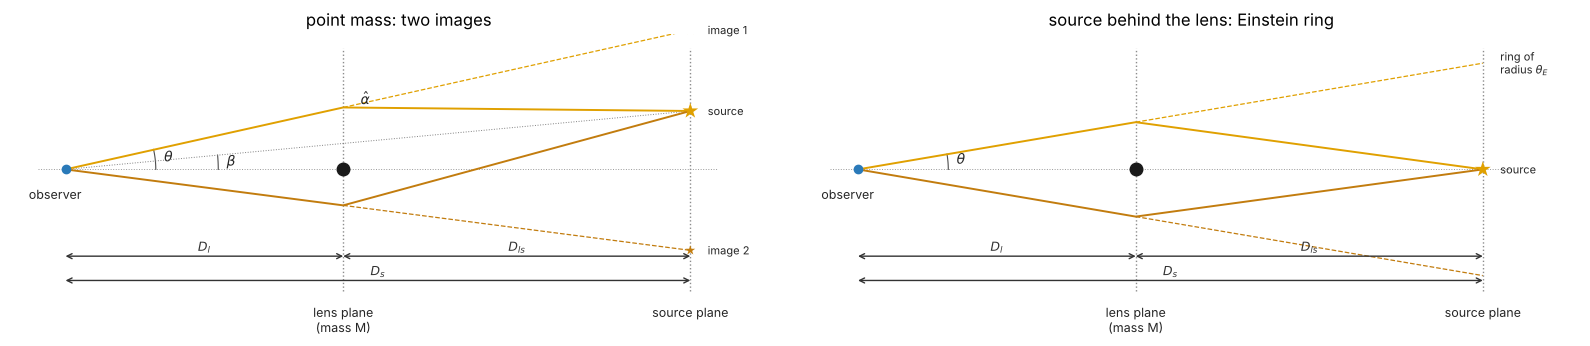

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(16, 4.2))
sketch.lensing_geometry(axs[0], title="point mass: two images")
sketch.lensing_geometry(axs[1], ring=True, title="source behind the lens: Einstein ring")
plt.tight_layout()
plt.show()

## 1. Light bending in a gradient-index medium

In the isotropic coordinates of a static weak field the light rays obey
Fermat's principle with $n = 1 - 2\Phi/c^2$. For a point mass this is
$n = 1 + R_s/r$; integrating $\nabla_\perp n$ along a straight line gives the
deflection $\hat\alpha = 2R_s/b$ (and $2R_s/b \cdot L/\sqrt{L^2+b^2}$ for a path
from $-L$ to $L$). Some numbers first:

In [3]:
R_sun = 6.957e8
Rs_sun = ln.schwarzschild_radius(ln.M_SUN)
print("Schwarzschild radius of the Sun: %.0f m; deflection at the limb %.3f arcsec"
      % (Rs_sun, ln.deflection_weak(R_sun, Rs_sun)/arcsec))
cases = [("a solar mass star at 4 kpc, source at 8 kpc (bulge)", ln.M_SUN, 4*ln.KPC, 8*ln.KPC),
         ("a 1e12 solar mass galaxy at 1 Gpc, source at 2 Gpc", 1e12*ln.M_SUN, 1000*ln.MPC, 2000*ln.MPC),
         ("a 1e15 solar mass cluster at 1 Gpc, source at 2 Gpc", 1e15*ln.M_SUN, 1000*ln.MPC, 2000*ln.MPC)]
for name, M, Dl, Ds in cases:
    tE = ln.einstein_radius(M, Dl, Ds)
    print("%-55s theta_E = %.3g arcsec" % (name, tE/arcsec))

Schwarzschild radius of the Sun: 2954 m; deflection at the limb 1.752 arcsec
a solar mass star at 4 kpc, source at 8 kpc (bulge)     theta_E = 0.00101 arcsec
a 1e12 solar mass galaxy at 1 Gpc, source at 2 Gpc      theta_E = 2.02 arcsec
a 1e15 solar mass cluster at 1 Gpc, source at 2 Gpc     theta_E = 63.8 arcsec


Now the rays. Lengths in units of $R_s$, rays from $z = -L$ to $z = L$ with
$L = 10^4\,R_s$, traced with `grin.trace()` through the weak field
index and through the exact Schwarzschild metric, which in isotropic
coordinates is also a medium (`schwarzschild_medium()`):

$$n = \frac{(1 + R_s/4\rho)^3}{1 - R_s/4\rho}.$$

Its exact deflection is the integral

$$\hat\alpha = 2\int_0^{u_0}\frac{du}{\sqrt{1/b^2 - u^2 + R_s u^3}} - \pi$$

over $u = 1/r$ up to the closest approach $u_0$ (`schwarzschild_deflection()`),
$2R_s/b + 15\pi R_s^2/(16 b^2) + \dots$ for large $b$.

weak medium: 10.8 s


exact medium: 52.3 s
   b/R_s  weak traced       2R_s/b exact traced     integral    2nd order
     3.0      0.91135      0.66667      1.71897      1.71939      0.99392
     5.7      0.40600      0.34961      0.48393      0.48400      0.43961
    10.9      0.19764      0.18334      0.21311      0.21314      0.20810
    20.8      0.09992      0.09615      0.10360      0.10361      0.10296
    39.7      0.05144      0.05042      0.05238      0.05238      0.05229
    75.6      0.02672      0.02644      0.02697      0.02697      0.02696
   144.2      0.01394      0.01387      0.01401      0.01401      0.01401
   275.0      0.00729      0.00727      0.00731      0.00731      0.00731
   524.4      0.00381      0.00381      0.00382      0.00382      0.00382
  1000.0      0.00199      0.00199      0.00199      0.00199      0.00199


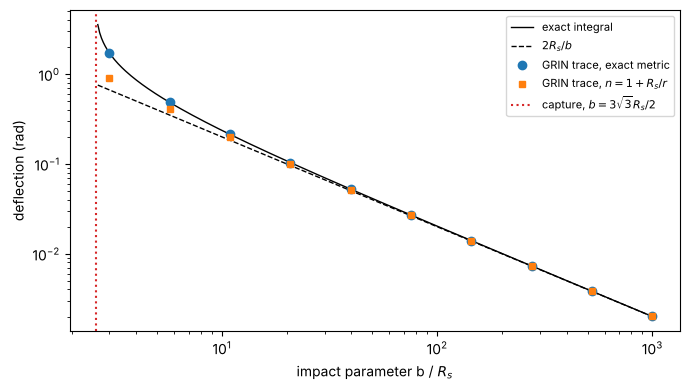

In [4]:
L = 1e4
b = np.geomspace(3.0, 1000, 10)
start = np.c_[b, -L*np.ones_like(b)]
stop = lambda r: np.minimum(np.linalg.norm(r, axis=1) - 0.3, L - r[:, 1])
traced = {}
for name, medium in (("weak", ln.weak_field_medium()), ("exact", ln.schwarzschild_medium())):
    t0 = time.time()
    rays = grin.trace(medium, start, [0, 1], step=0.25, stop=stop, record=False, max_steps=400000)
    d = rays.direction
    traced[name] = np.arctan2(-d[:, 0], d[:, 1])
    print("%s medium: %.1f s" % (name, time.time() - t0))
finite = L/np.hypot(L, b)
exact = ln.schwarzschild_deflection(b)
print("%8s %12s %12s %12s %12s %12s" % ("b/R_s", "weak traced", "2R_s/b", "exact traced",
                                         "integral", "2nd order"))
for k in range(len(b)):
    print("%8.1f %12.5f %12.5f %12.5f %12.5f %12.5f"
          % (b[k], traced["weak"][k], 2/b[k]*finite[k], traced["exact"][k], exact[k]*finite[k],
             ln.deflection_second_order(b[k])*finite[k]))

fig, ax = plt.subplots(figsize=(7, 4))
bb = np.geomspace(2.65, 1000, 300)
ax.loglog(bb, ln.schwarzschild_deflection(bb), "k-", lw=1, label="exact integral")
ax.loglog(bb, ln.deflection_weak(bb), "k--", lw=1, label="$2R_s/b$")
ax.loglog(b, traced["exact"]/finite, "o", label="GRIN trace, exact metric")
ax.loglog(b, traced["weak"]/finite, "s", ms=4, label="GRIN trace, $n = 1 + R_s/r$")
ax.axvline(1.5*np.sqrt(3), color="C3", ls=":", label="capture, $b = 3\\sqrt{3}R_s/2$")
ax.set_xlabel("impact parameter b / $R_s$")
ax.set_ylabel("deflection (rad)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Far from the mass both media give $2R_s/b$. The weak field index also
reproduces part of the second order, but only the exact medium follows
the exact deflection (to a few $10^{-4}$, the residual of the finite path), all
the way down to strong bending. At the photon sphere $r = 3R_s/2$ (impact
parameter $3\sqrt{3}R_s/2 \approx 2.6R_s$) light can circle the mass; rays
just outside it wind around before escaping, rays inside fall in. Close
to the critical impact parameter:

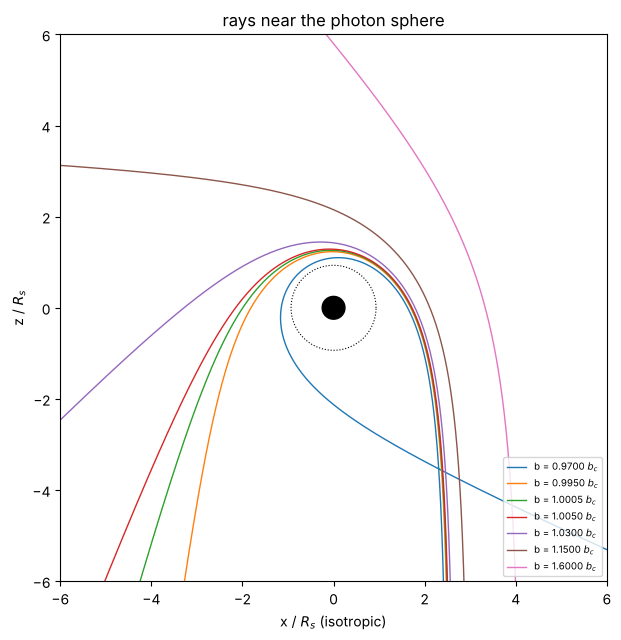

In [5]:
b_c = 1.5*np.sqrt(3)
bs = b_c*np.array([0.97, 0.995, 1.0005, 1.005, 1.03, 1.15, 1.6])
L2 = 25.0
start = np.c_[bs, -L2*np.ones_like(bs)]
stop2 = lambda r: np.minimum(np.linalg.norm(r, axis=1) - 0.27, 30 - np.linalg.norm(r, axis=1))
rays = grin.trace(ln.schwarzschild_medium(), start, [0, 1], step=0.01, stop=stop2, max_steps=200000)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for k in range(len(bs)):
    p = rays.path[:, k]
    ax.plot(p[:, 0], p[:, 1], lw=1, label="b = %.4f $b_c$" % (bs[k]/b_c))
t = np.linspace(0, 2*np.pi, 200)
rho_h = 0.25                                     # horizon in isotropic coordinates
rho_ps = (2 + np.sqrt(3))/4                      # photon sphere r = 3/2 in isotropic coordinates
ax.fill(rho_h*np.cos(t), rho_h*np.sin(t), color="k")
ax.plot(rho_ps*np.cos(t), rho_ps*np.sin(t), "k:", lw=0.8)
ax.set_xlim(-6, 6)
ax.set_ylim(-6, 6)
ax.set_aspect("equal")
ax.set_xlabel("x / $R_s$ (isotropic)")
ax.set_ylabel("z / $R_s$")
ax.legend(fontsize=7, loc="lower right")
ax.set_title("rays near the photon sphere")
plt.tight_layout()
plt.show()

## 2. The point mass lens

With angles in units of $\theta_E$ and the source at $u = \beta/\theta_E$ the
lens equation $u = \theta - 1/\theta$ has two solutions,

$$\theta_\pm = \frac{u \pm \sqrt{u^2+4}}{2},$$

one outside the Einstein ring on the side of the source and one inside on
the other side. Surface brightness is conserved, so an image is magnified
by the ratio of its solid angle to that of the source, $\mu = 1/\det(\partial\beta/\partial\theta)$:

$$\mu_\pm = \frac{u^2+2}{2u\sqrt{u^2+4}} \pm \frac12, \qquad \mu = \mu_+ + \mu_- = \frac{u^2+2}{u\sqrt{u^2+4}}.$$

`find_images()` solves the lens equation for any lens by Newton
iterations, `magnification()` evaluates the Jacobian numerically:

In [6]:
pm = ln.PointMass()
print("%6s %22s %22s %18s %18s" % ("u", "theta (found)", "theta (formula)", "mu (found)",
                                    "mu (formula)"))
for u in (0.05, 0.2, 0.5, 1.0, 2.0):
    th, mu = ln.find_images(pm, (u, 0.0))
    tp, tm, mp, mm = ln.point_mass_images(u)
    order = np.argsort(-th[:, 0])
    print("%6.2f %10.5f %10.5f %10.5f %10.5f %8.4f %8.4f %8.4f %8.4f"
          % (u, *th[order, 0], tp, tm, *np.abs(mu[order]), mp, mm))

     u          theta (found)        theta (formula)         mu (found)       mu (formula)


  0.05    1.02531   -0.97531    1.02531   -0.97531  10.5094   9.5094  10.5094   9.5094
  0.20    1.10499   -0.90499    1.10499   -0.90499   3.0373   2.0373   3.0373   2.0373


  0.50    1.28078   -0.78078    1.28078   -0.78078   1.5914   0.5914   1.5914   0.5914
  1.00    1.61803   -0.61803    1.61803   -0.61803   1.1708   0.1708   1.1708   0.1708


  2.00    2.41421   -0.41421    2.41421   -0.41421   1.0303   0.0303   1.0303   0.0303


## 3. Rings and arcs: extended sources

An extended source is imaged by inverse ray shooting: every pixel of the
image plane is mapped back to the source plane with the lens equation and
takes the surface brightness found there (`ray_shoot()`). A source exactly
behind the lens becomes a ring, a slightly offset one two arcs. The flux
magnification of a uniform disk source of radius $\rho$ centred behind a
point mass is $\sqrt{1 + 4/\rho^2}$ (Witt and Mao):

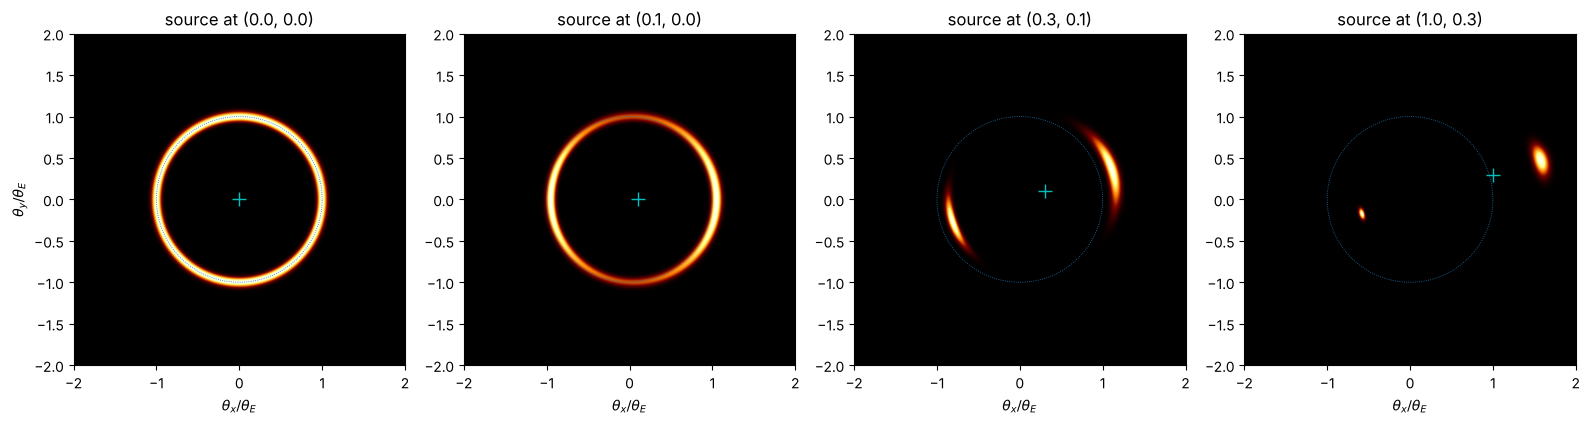

     rho   ray shooting sqrt(1+4/rho^2)
    0.05        40.0212        40.0125
    0.10        20.0360        20.0250


    0.30         6.7419         6.7412
    1.00         2.2364         2.2361


In [7]:
x = np.linspace(-2, 2, 801)
dx = x[1] - x[0]
rho = 0.15
fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (bx, by) in zip(axs, ((0, 0), (0.1, 0), (0.3, 0.1), (1.0, 0.3))):
    src = lambda X, Y: np.exp(-((X - bx)**2 + (Y - by)**2)/(2*(rho/2)**2))
    I = ln.ray_shoot(pm, src, x, x)
    ax.imshow(I, extent=(x[0], x[-1], x[0], x[-1]), origin="lower", cmap="afmhot")
    t = np.linspace(0, 2*np.pi, 200)
    ax.plot(np.cos(t), np.sin(t), color="C0", lw=0.6, ls=":")
    ax.plot(bx, by, "c+", ms=10)
    ax.set_title("source at (%.1f, %.1f)" % (bx, by))
    ax.set_xlabel(r"$\theta_x/\theta_E$")
axs[0].set_ylabel(r"$\theta_y/\theta_E$")
plt.tight_layout()
plt.show()

print("%8s %14s %14s" % ("rho", "ray shooting", "sqrt(1+4/rho^2)"))
for rho_ in (0.05, 0.1, 0.3, 1.0):
    disk = lambda X, Y: (X**2 + Y**2 < rho_**2).astype(float)
    xx = np.linspace(-(1 + rho_)*1.1, (1 + rho_)*1.1, 1201)
    I = ln.ray_shoot(pm, disk, xx, xx)
    mu = I.sum()*(xx[1] - xx[0])**2/(np.pi*rho_**2)
    print("%8.2f %14.4f %14.4f" % (rho_, mu, ln.finite_source_magnification(rho_)))

The ring sits at $\theta_E$ (dotted). A small source of radius $\rho$
becomes a ring of radius 1 and width $\approx\rho$: area $\approx 2\pi\rho$
against the source's $\pi\rho^2$, hence $\mu \approx 2/\rho$, the small $\rho$
limit of the formula. For large sources the magnification tends to 1.

## 4. Microlensing light curves

A star of the Galactic bulge passing behind a star of the disk at the
relative angular speed $\theta_E/t_E$ moves along $u(t) = \sqrt{u_0^2 +
((t - t_0)/t_E)^2}$ in the source plane. The two images are a
milliarcsecond apart and cannot be resolved; what is seen is the total
magnification, the Paczyński curve $\mu(u(t))$. The magnification of a
small disk source by ray shooting (the grid reaches $3\theta_E$, so it holds the outer image
up to $u \approx 2.3$) against the point source curve:

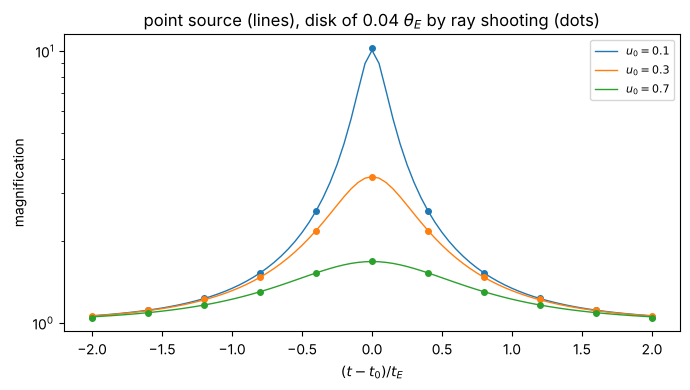

In [8]:
tt = np.linspace(-2, 2, 81)
rho_s = 0.04
xx = np.linspace(-3.0, 3.0, 1501)
fig, ax = plt.subplots(figsize=(7, 4))
for u0, col in ((0.1, "C0"), (0.3, "C1"), (0.7, "C2")):
    u = np.sqrt(u0**2 + tt**2)
    ax.semilogy(tt, ln.paczynski(u), color=col, lw=1, label="$u_0 = %.1f$" % u0)
    tt_s = tt[::8]
    mus = []
    for t_ in tt_s:
        disk = lambda X, Y: ((X - t_)**2 + (Y - u0)**2 < rho_s**2).astype(float)
        I = ln.ray_shoot(pm, disk, xx, xx)
        mus.append(I.sum()*(xx[1] - xx[0])**2/(np.pi*rho_s**2))
    ax.semilogy(tt_s, mus, "o", color=col, ms=4)
ax.set_xlabel("$(t - t_0)/t_E$")
ax.set_ylabel("magnification")
ax.set_title("point source (lines), disk of 0.04 $\\theta_E$ by ray shooting (dots)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The dots follow the point source curves to about 1 %, the pixel
noise of the grid. At the peak of the $u_0 = 0.1$ curve the disk is 2 %
brighter: the start of the finite source effect, which takes over once
the source radius approaches $u_0$.

## 5. A galaxy: the singular isothermal sphere

Galaxies have nearly flat rotation curves, which the singular isothermal
sphere $\rho \propto 1/r^2$ models. Its deflection has the same magnitude
$\theta_E = 4\pi(\sigma_v/c)^2 D_{ls}/D_s$ everywhere (velocity dispersion
$\sigma_v$). For $\beta < \theta_E$ there are two images at $\beta \pm \theta_E$ with the
magnifications $|\theta|/(|\theta| - \theta_E)$, total $2\theta_E/\beta$; for $\beta > \theta_E$
only one.

The arrival time of a ray from the source through $\theta$ is, up to a
factor $D_l D_s/(c D_{ls})$, the Fermat potential

$$\tau(\theta) = \tfrac12|\theta - \beta|^2 - \psi(\theta),$$

geometric path minus the potential (Shapiro) delay, with the lens potential
$\psi = \theta_E|\theta|$ for the SIS. Images are where $\tau$ is stationary
(Fermat's principle): a minimum and a saddle point. The delay between
the two images of an SIS is $2\beta\theta_E$:

images: [-0.65  1.35]  formula: [ 1.35 -0.65]
magnifications: [-1.85714  3.85714]  formula: [ 3.85714 -1.85714]
delay: 0.700000, formula 2 beta theta_E = 0.700000
for theta_E = 1 arcsec, D_l = 1 Gpc, D_s = 2 Gpc: 39.2 days


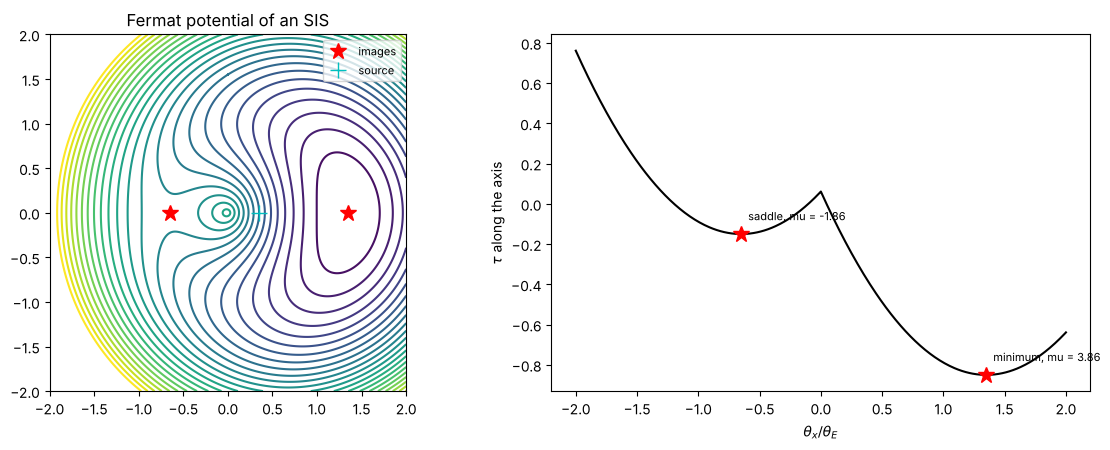

In [9]:
sis = ln.SIS()
beta = np.array([0.35, 0.0])
th, mu = ln.find_images(sis, beta)
th_a, mu_a = ln.sis_images(beta[0])
tau = ln.fermat_potential(sis, th, beta)
print("images:", np.round(th[:, 0], 6), " formula:", th_a)
print("magnifications:", np.round(mu, 5), " formula:", np.round(mu_a, 5))
print("delay: %.6f, formula 2 beta theta_E = %.6f" % (abs(tau[1] - tau[0]), 2*beta[0]))
# time delay of a real lens: theta_E = 1 arcsec, D_l = 1 Gpc, D_s = 2 Gpc
Dl, Ds = 1000*ln.MPC, 2000*ln.MPC
scale = Dl*Ds/(ln.C*(Ds - Dl))*arcsec**2
print("for theta_E = 1 arcsec, D_l = 1 Gpc, D_s = 2 Gpc: %.1f days" % (2*0.35*scale/86400))

g = np.linspace(-2, 2, 401)
T = np.stack(np.meshgrid(g, g), axis=-1)
F = ln.fermat_potential(sis, T, beta)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
cs = axs[0].contour(g, g, F, levels=np.linspace(F.min(), F.min() + 1.5, 25), cmap="viridis")
axs[0].plot(th[:, 0], th[:, 1], "r*", ms=12, label="images")
axs[0].plot(*beta, "c+", ms=12, label="source")
axs[0].set_aspect("equal")
axs[0].set_title("Fermat potential of an SIS")
axs[0].legend(fontsize=8)
axs[1].plot(g, F[200], "k-")
for t_, m_ in zip(th[:, 0], mu):
    axs[1].plot(t_, ln.fermat_potential(sis, [t_, 0.0], beta), "r*", ms=12)
    axs[1].annotate("%s, mu = %.2f" % ("minimum" if m_ > 0 else "saddle", m_),
                    (t_, ln.fermat_potential(sis, [t_, 0.0], beta)), textcoords="offset points",
                    xytext=(5, 10), fontsize=8)
axs[1].set_xlabel(r"$\theta_x/\theta_E$")
axs[1].set_ylabel(r"$\tau$ along the axis")
plt.tight_layout()
plt.show()

The image at the minimum arrives first and is magnified with positive
parity; the saddle point image arrives $2\beta\theta_E$ later, mirror
inverted. Measured delays between the images of a variable quasar give
the scale of the lens, $D_l D_s/D_{ls}$, and with it the Hubble constant
(Refsdal 1964).

## 6. An isothermal galaxy in a tidal field: caustics and the Einstein cross

A real lens galaxy is not alone: its neighbours add a tidal field, an
external shear $\gamma$ with the potential $\frac{\gamma}{2}(x^2 - y^2)$. The
circular symmetry is broken. The Einstein ring, where $\det(\partial\beta/
\partial\theta) = 0$ (the critical curve), maps to a caustic in the source
plane that is no longer a point but an astroid with four cusps. Sources
inside it have four images (plus one at the singular centre that the SIS
suppresses): the Einstein cross. Crossing a caustic adds or removes two
images, which merge on the critical curve with infinite magnification.
On the axes of the shear the cusps lie at

$$\beta_x = \frac{2\gamma\theta_E}{1+\gamma}, \qquad \beta_y = \frac{2\gamma\theta_E}{1-\gamma}$$

(from the Jacobian on the axes, where it is diagonal):

cusps on x: 0.26087 (formula 0.26087), on y: 0.35294 (formula 0.35294)


image counts found: [np.int64(2), np.int64(4)]


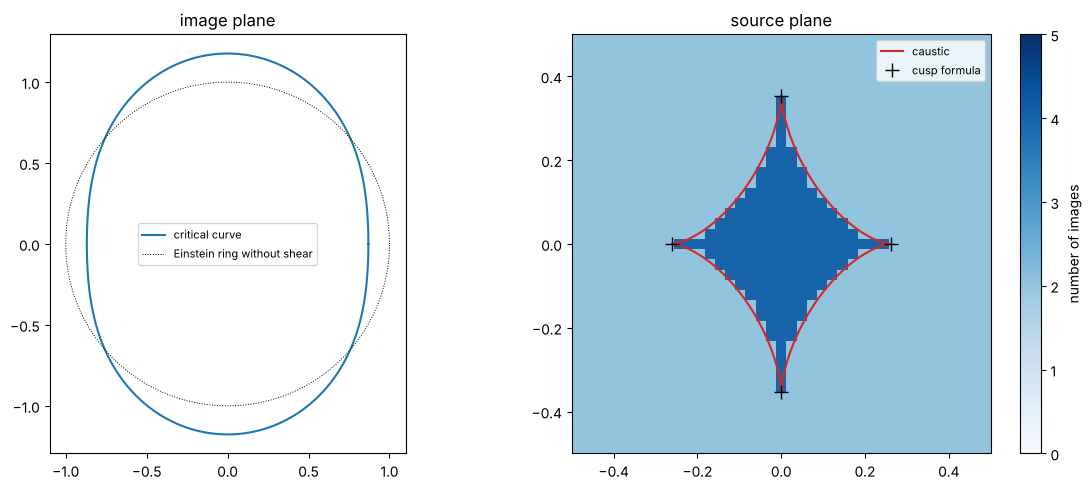

In [10]:
gam = 0.15
lens = ln.Composite([ln.SIS(), ln.ExternalShear(gam)])
cc = ln.critical_curve(lens, n_angles=721)
ca = ln.caustic(lens, cc)
cx, cy = ln.sis_shear_cusps(gam)
print("cusps on x: %.5f (formula %.5f), on y: %.5f (formula %.5f)"
      % (np.nanmax(np.abs(ca[0][:, 0])), cx, np.nanmax(np.abs(ca[0][:, 1])), cy))

# number of images over the source plane
bg = np.linspace(-0.5, 0.5, 41)
nimg = np.zeros((len(bg), len(bg)), int)
for i, by in enumerate(bg):
    for j, bx in enumerate(bg):
        nimg[i, j] = len(ln.find_images(lens, (bx, by), extent=2.5, n=41)[0])
print("image counts found:", sorted(set(nimg.ravel())))

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].plot(cc[0][:, 0], cc[0][:, 1], "C0-", label="critical curve")
t = np.linspace(0, 2*np.pi, 200)
axs[0].plot(np.cos(t), np.sin(t), "k:", lw=0.7, label="Einstein ring without shear")
axs[0].set_aspect("equal")
axs[0].set_title("image plane")
axs[0].legend(fontsize=8)
im = axs[1].imshow(nimg, extent=(bg[0], bg[-1], bg[0], bg[-1]), origin="lower", cmap="Blues",
                   vmin=0, vmax=5)
plt.colorbar(im, ax=axs[1], label="number of images")
axs[1].plot(ca[0][:, 0], ca[0][:, 1], "C3-", label="caustic")
axs[1].plot([cx, -cx, 0, 0], [0, 0, cy, -cy], "k+", ms=10, label="cusp formula")
axs[1].set_aspect("equal")
axs[1].set_title("source plane")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Extended sources at different positions relative to the caustic: inside
near the centre (an Einstein cross), near a cusp (three images merge into
a bright arc), on a fold (two images merge), and outside (two images).
The source is drawn in the inset at the same scale.

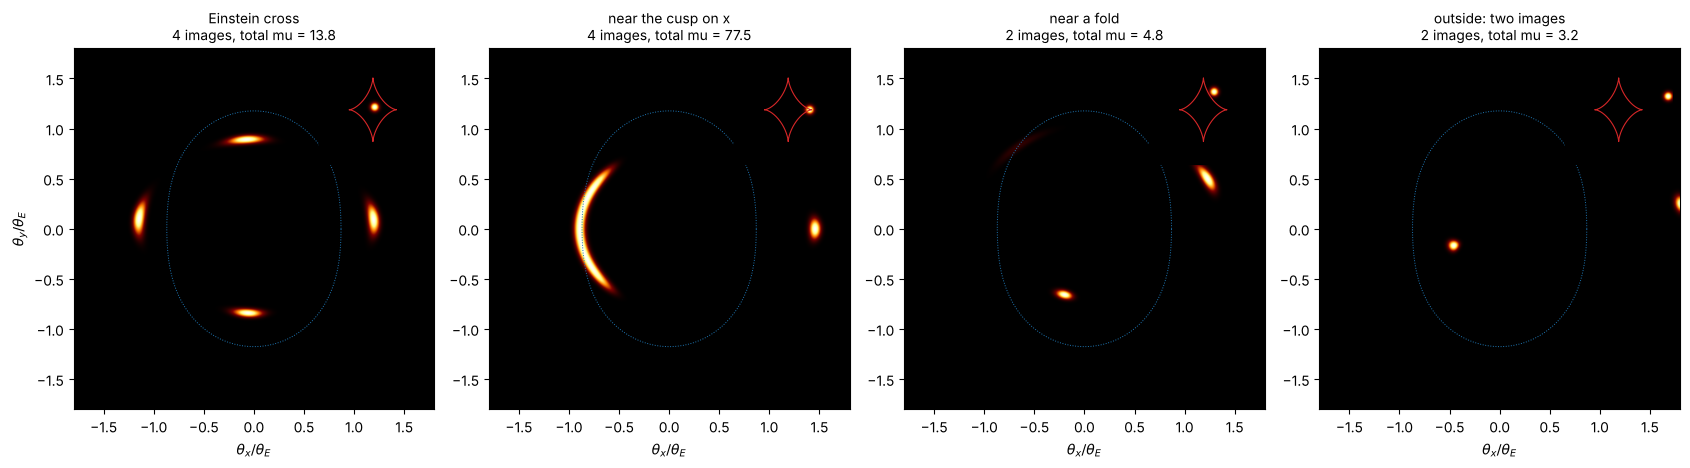

In [11]:
x = np.linspace(-1.8, 1.8, 721)
cases = [((0.02, 0.03), "Einstein cross"), ((0.24, 0.0), "near the cusp on x"),
         ((0.12, 0.2), "near a fold"), ((0.55, 0.15), "outside: two images")]
fig, axs = plt.subplots(1, 4, figsize=(17, 4.4))
for ax, (b0, title) in zip(axs, cases):
    src = lambda X, Y: np.exp(-((X - b0[0])**2 + (Y - b0[1])**2)/(2*0.03**2))
    I = ln.ray_shoot(lens, src, x, x)
    ax.imshow(I, extent=(x[0], x[-1], x[0], x[-1]), origin="lower", cmap="afmhot")
    ax.plot(cc[0][:, 0], cc[0][:, 1], "C0:", lw=0.7)
    th, mu = ln.find_images(lens, b0, extent=2.0, n=61)
    ax.set_title("%s\n%d images, total mu = %.1f" % (title, len(th), np.sum(np.abs(mu))), fontsize=10)
    ins = ax.inset_axes([0.68, 0.68, 0.3, 0.3])
    ins.plot(ca[0][:, 0], ca[0][:, 1], "C3-", lw=0.8)
    S = src(*np.meshgrid(x/3, x/3))
    ins.imshow(S, extent=(x[0]/3, x[-1]/3, x[0]/3, x[-1]/3), origin="lower", cmap="afmhot")
    ins.set_xticks([])
    ins.set_yticks([])
    ax.set_xlabel(r"$\theta_x/\theta_E$")
axs[0].set_ylabel(r"$\theta_y/\theta_E$")
plt.tight_layout()
plt.show()

## Summary

- In the weak field a mass is a gradient-index medium $n = 1 + R_s/r$; the
  traced deflection is $2R_s/b$ (1.75″ at the Sun). The exact
  Schwarzschild metric is an isotropic medium too and reproduces the
  exact deflection integral, including strong bending and the capture of
  rays inside $b = 3\sqrt{3}R_s/2$.
- The thin lens equation $\beta = \theta - \alpha(\theta)$ gives the images: for a
  point mass at $(u \pm \sqrt{u^2+4})/2$ with the magnifications of the
  closed form, the Paczyński curve for their sum, and $\sqrt{1+4/\rho^2}$
  for a disk source behind the lens.
- An isothermal galaxy makes two images ($2\theta_E/\beta$ magnification) at
  a minimum and a saddle of the Fermat potential, delayed by $2\beta\theta_E$.
- A tidal shear turns the point caustic into an astroid with cusps at
  $2\gamma\theta_E/(1\pm\gamma)$: four images inside (the Einstein cross), arcs where
  images merge on the critical curve.

## References

- A. Einstein, "Lens-like action of a star by the deviation of light in
  the gravitational field", Science 84, 506–507 (1936).
- F. W. Dyson, A. S. Eddington and C. Davidson, "A determination of the
  deflection of light by the Sun's gravitational field", Phil. Trans. R.
  Soc. A 220, 291–333 (1920).
- S. Refsdal, "On the possibility of determining Hubble's parameter and
  the masses of galaxies from the gravitational lens effect", Mon. Not.
  R. Astron. Soc. 128, 307–310 (1964).
- B. Paczyński, "Gravitational microlensing by the galactic halo",
  Astrophys. J. 304, 1–5 (1986).
- H. J. Witt and S. Mao, "Can lensed stars be regarded as pointlike for
  microlensing by MACHOs?", Astrophys. J. 430, 505–510 (1994).
- P. Schneider, J. Ehlers and E. E. Falco, *Gravitational Lenses*,
  Springer (1992).
- R. Narayan and M. Bartelmann, "Lectures on gravitational lensing",
  arXiv:astro-ph/9606001 (1996).
- C. W. Misner, K. S. Thorne and J. A. Wheeler, *Gravitation*, Freeman
  (1973), exercise 25.27 (isotropic coordinates).

In [12]:
print("notebook run time %.0f s" % (time.time() - t_start))

notebook run time 151 s
